In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
from pathlib import Path

if 'google.colab' in sys.modules:
    repo_name = "study-mikanos"
    repo_url = "https://github.com/miyayudai/study-mikanos.git"
    if not os.path.exists(f"/content/{repo_name}"):
        print(f"{repo_name} リポジトリをダウンロード中...")
        !git clone {repo_url} > /dev/null 2>&1
    
    print("必要な依存パッケージをインストール中...")
    %cd /content/{repo_name}
    !pip install -q -r requirements.txt
    !pip install -q -e .
    
    print("作業ディレクトリを該当章へ移動中...")
    %cd /content/{repo_name}/1
    print("✅ 準備完了！このまま下のセルを実行して学習を開始できます。")
else:
    _repo_root = Path.cwd().parent if Path.cwd().name == '1' else Path.cwd()
    if str(_repo_root) not in sys.path:
        sys.path.insert(0, str(_repo_root))
    print("✅ ローカル環境で実行中: リポジトリルートを sys.path に設定しました。")


✅ ローカル環境で実行中: リポジトリルートを sys.path に設定しました。


# 第1章 PCの仕組みとハローワールド — 1.5 結局、何をやったのか？ (*What Actually Happened Behind the Scenes*)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/1/1.5_What_Actually_Happened.ipynb)

これまでの 1.1〜1.4 節において、私たちはバイナリエディタで手打ちした機械語バイナリを USB メモリや QEMU の所定のディレクトリ（`\EFI\BOOT\BOOTX64.EFI`）に配置し、PC や仮想マシンを起動することで画面に `"Hello, world"` という文字列を表示させることに成功しました。

しかし、立ち止まって考えてみてください。
- **電源ボタンを押した瞬間、CPU は誰から命令をもらって動き出したのでしょうか？**
- **まだ OS もないのに、PC はどうやって USB メモリやディスクの中からファイルを見つけ出したのでしょうか？**
- **なぜファイル名が `BOOTX64.EFI` で、フォルダが `/EFI/BOOT/` でなければならなかったのでしょうか？**
- **画面に文字が表示されるまでの間、メモリやレジスタ、CPU の動作モード（16ビット/32ビット/64ビット）はどのように移り変わっていたのでしょうか？**

OS 自作とは、これら**「現代の PC がブラックボックスの中に隠蔽してきたハードウェアとファームウェアの全歴史と動作原理」**を一枚ずつ剥ぎ取っていく知的な冒険です。
本節では、PC の電源スイッチが入ったナノ秒単位のハードウェア初期化から、CPU リセットベクタ、UEFI PI 5大ブートフェーズ、標準ブートパスフォールバック、PE32+ ローダ、そして `EfiMain` 呼び出しと画面描画に至るまでの**全実行シーケンスの完全トレース**を行います。

---

### 🎯 本節の学習目標 (Learning Objectives)
1. **CPU リセットベクタ (*Reset Vector*) の物理アドレス数理**:
   - x86-64 CPU が電源投入直後に `0xFFFFFFF0`（4GiB - 16B）から実行を開始する理由と、隠し CS ベースレジスタの仕組みを理解する。
2. **UEFI PI (*Platform Initialization*) 5大フェーズの役割と状態遷移**:
   - **SEC** (*Security*), **PEI** (*Pre-EFI Initialization*), **DXE** (*Driver Execution Environment*), **BDS** (*Boot Device Selection*), **TSL** (*Transient System Load*) における CPU モードとメモリバック（CAR → DRAM → ページング）の推移を解明する。
3. **UEFI 仕様書 Section 3.5 に基づくデフォルトブートフォールバック仕様**:
   - なぜ `\EFI\BOOT\BOOTX64.EFI` というパス・ファイル名が国際規格として定められているのか、マルチアーキテクチャ対応を含めて数理的に把握する。
4. **PE32+ 実行可能ファイルのメモリロードと Microsoft x64 ABI**:
   - UEFI がバイナリを任意のアドレスへ再配置（Relocation）し、`RCX=ImageHandle`, `RDX=SystemTable` で呼び出す規約を追跡する。
5. **C++20 & Python ハイブリッドシミュレータによる動作検証**:
   - ブートマネージャの探索決定木と CPU レジスタ状態の整合性をプログラムで厳密に実証する。


## 1. 電源投入から CPU 最初の一歩 — リセットベクタ (*Reset Vector*) の数理

### 電源投入（Power-On）とハードウェア初期化
PC の電源ボタンを押すと、電源ユニット（PSU: *Power Supply Unit*）からマザーボード各部へ +12V, +5V, +3.3V の電圧が供給されます。電圧が安定すると、PSU はチップセットへ **Power Good** 信号を送信します。
この信号を受信したクロックジェネレータがクロック信号の発振を開始し、CPU の `RESET#` ピンのアサート（Low）が解除（De-assert）されます。この瞬間、CPU は初めて命令のフェッチ（Fetch: 読み出し）を開始します。

### x86-64 CPU の初期レジスタ状態
Intel 64 / AMD64 アーキテクチャの CPU は、最新の 64ビット CPU であっても、電源投入・ハードウェアリセット直後は**1978年の 16ビット CPU（Intel 8086）との完全な後方互換モード（リアルモード相当）**で起動します。

Intel Software Developer's Manual (Intel SDM Vol 3A, Section 9.1.4) によると、リセット直後の主要レジスタは以下のように厳密に初期化されます：

| レジスタ | 初期値 | 意味・役割 |
|---|---|---|
| **`RIP`** (命令ポインタ) | `0x0000FFF0` | 16ビットのオフセットアドレス |
| **`CS`** (コードセグメント・セレクタ) | `0xF000` | リアルモード互換セレクタ値 |
| **`CS` (非表示ベースアドレス)** | `0xFFFF0000` | CPU 内部ディスクリプタキャッシュに保持されるベースアドレス |
| **`CR0`** (制御レジスタ 0) | `0x60000010` | `PE=0` (リアルモード), `CD=1` (キャッシュ無効), `NW=1` (ライトスルー禁止) |
| **`EFLAGS`** (フラグレジスタ) | `0x00000002` | 予約ビット（bit 1）のみが 1 |
| **`EDX`** (BIST 結果) | `0x00000000` | 内蔵自己診断 (*Built-In Self Test*) 成功コードおよび CPU ファミリ情報 |

### 物理リセットベクタの導出数理
通常、リアルモードのアドレス計算は `セグメント × 16 + オフセット` です。もし `0xF000 × 16 + 0xFFF0` だとすると `0x000FFFF0`（1MB の 16バイト手前）になってしまいます。
しかし、32ビット/64ビット CPU では、リセット直後の `CS` セグメントの隠しベースアドレスレジスタに `0xFFFF0000` が強制ロードされます。
したがって、CPU が最初にフェッチする物理アドレス（**リセットベクタ: *Reset Vector***）は以下のようになります：

$$\text{Reset Vector} = \text{CS}_{\text{base}} + \text{RIP} = \text{0xFFFF0000} + \text{0x0000FFF0} = \text{0xFFFFFFF0}$$

これは、32ビット物理アドレス空間の最上端（$2^{32} = 4\,\text{GiB} = \text{0x100000000}$）のわずか **16バイト手前** のアドレスです：

$$\text{Distance from 4GiB} = \text{0x100000000} - \text{0xFFFFFFF0} = 16\,\text{bytes}$$

```text
32ビット物理アドレス空間 (0x00000000 〜 0xFFFFFFFF, 4 GiB)
┌────────────────────────────────────────────────────────┐ 0xFFFFFFFF (4 GiB)
│ ▲ 16バイトの空間                                        │
│ ★ リセットベクタ (0xFFFFFFF0) : JMP 命令が配置される   │ 0xFFFFFFF0 (4 GiB - 16B)
├────────────────────────────────────────────────────────┤
│ SPI Flash ROM 領域 (UEFI BIOS ファームウェア)          │ e.g. 0xFF000000 〜 0xFFFFFFFF (16 MiB)
├────────────────────────────────────────────────────────┤
│ MMIO 領域 / PCI コンフィギュレーション空間              │
├────────────────────────────────────────────────────────┤
│ メインメモリ (DRAM) 領域 (※電源投入直後はまだ未初期化) │ 0x00000000 〜 (DRAM容量)
└────────────────────────────────────────────────────────┘ 0x00000000
```

> [!NOTE]
> **なぜメモリの最上端（4GiB - 16バイト）なのか？**  
> PC の電源を入れた瞬間、マザーボード上の DRAM（メインメモリ）は電気的特性の較正が行われておらず、1バイトも読み書きできません。  
> そのため、CPU はメモリバスのアドレスデコーダにより、マザーボード上の **SPI Flash ROM（UEFI BIOS チップ）** がマッピングされている `0xFF000000` 以降の最上部メモリ領域から直接コードを読み出します。  
> 16バイトというごく狭い空間には、即座に Flash ROM 下部の初期化ルーチンへジャンプする `JMP` 命令（5バイト）だけが書き込まれています。


In [2]:
# Python による x86-64 CPU ハードウェアリセットベクタの数理検証
from common import CpuResetVector

reset_vec = CpuResetVector()
summary = reset_vec.summary()

print("=" * 65)
print("x86-64 CPU Power-On Reset State Verification")
print("=" * 65)
for key, val in summary.items():
    print(f"  {key:<26}: {val}")

assert reset_vec.physical_address == 0xFFFF_FFF0, "Reset vector must be 0xFFFFFFF0"
assert reset_vec.distance_from_4gib == 16, "Reset vector must be 16 bytes below 4GiB"
print("\n✅ ハードウェアリセットベクタの導出値が Intel SDM 仕様と 100% 一致します。")


x86-64 CPU Power-On Reset State Verification
  physical_reset_vector     : 0xFFFFFFF0
  distance_from_4gib_bytes  : 16
  cs_ip                     : 0xF000:0xFFF0
  cs_base                   : 0xFFFF0000
  cr0                       : 0x60000010
  pe_bit                    : 0
  cd_bit                    : 1
  eflags                    : 0x00000002
  bist_passed               : True

✅ ハードウェアリセットベクタの導出値が Intel SDM 仕様と 100% 一致します。


## 2. UEFI Platform Initialization (PI) 5大ブートフェーズの完全解剖

リセットベクタの `JMP` 命令から始まるプログラムは、かつてのレガシー BIOS であればそのまま 16ビットリアルモードで MBR を読み込みにいきました。
しかし現代の **UEFI (*Unified Extensible Firmware Interface*)** では、セキュリティ、拡張性、モジュール性を担保するため、Intel が策定した **UEFI PI (*Platform Initialization*) 仕様** に基づく **5大ブートフェーズ** を厳格に順番に遷移していきます。

```mermaid
flowchart TD
    PowerOn["1. Power-On Reset\n(0xFFFFFFF0 / 16B below 4GB)"] --> SEC
    
    subgraph PI_Phases ["UEFI Platform Initialization (PI) 5大フェーズ"]
        SEC["2. SEC (Security Phase)\nMode: 32-bit Protected Mode\nMemory: Cache-as-RAM (CAR)\nRole: Hardware Root of Trust"]
        SEC --> PEI["3. PEI (Pre-EFI Initialization)\nMode: 32-bit Protected Mode\nMemory: CAR -> Main DRAM\nRole: Memory Controller Init, HOBs"]
        PEI --> DXE["4. DXE (Driver Execution Env)\nMode: 64-bit Long Mode (PML4)\nMemory: Physical DRAM\nRole: Dispatch GOP, USB, FAT Drivers"]
        DXE --> BDS["5. BDS (Boot Device Selection)\nMode: 64-bit Long Mode\nMemory: Physical DRAM\nRole: Enforce Boot Policy, Find BOOTX64.EFI"]
        BDS --> TSL["6. TSL (Transient System Load)\nMode: 64-bit Long Mode\nMemory: Physical DRAM\nRole: Execute EfiMain (MikanOS)"]
    end
    
    TSL --> RT["7. RT (Run Time Phase)\nKernel takes control via ExitBootServices()"]
```

---

### 各フェーズの内部メカニズムとハードウェア状態遷移

#### ① SEC (Security Phase) — 信頼の起点と Cache-as-RAM (CAR)
- **CPU 動作モード**: 16ビットリアルモードから即座に **32ビット保護モード (Protected Mode)** へ移行。
- **メモリ環境**: **Cache-as-RAM (CAR)**
  - DRAM がまだ使えないため、CPU の L1/L2 キャッシュを MTRR (*Memory Type Range Registers*) により `No-Eviction Mode`（ライトバック禁止・追い出し禁止）に設定し、**CPU キャッシュそのものを一時的な RAM（スタック領域）** として利用します。
- **主要な役割**:
  - 電源投入直後のハードウェア完全性検証（Root of Trust）。
  - BIST (*Built-In Self Test*) 結果の確認。
  - 一時スタックポインタと初期 PPI (*PEI Program Interface*) テーブルを作成し、PEI Foundation へ制御を移譲。

#### ② PEI (Pre-EFI Initialization Phase) — メモリコントローラ初期化と DRAM 検出
- **CPU 動作モード**: 32ビット保護モード。
- **メモリ環境**: CAR から **物理 DRAM (メインメモリ)** への移行。
- **主要な役割**:
  - 各種 PEIM (*PEI Module*) を実行。
  - マザーボードのチップセット初期化、および DDR4/DDR5 メモリコントローラのキャリブレーション（電気的信号タイミング、SPD の読み取り）。
  - DRAM が利用可能になると、一時的な CAR スタックのデータを DRAM へ退避（Migration）。
  - システムのメモリ構成、予約領域、ファームウェア配置情報を構造化した **HOB (*Hand-Off Block*) リスト** をメモリ上に構築し、DXE へ引き渡す。

#### ③ DXE (Driver Execution Environment Phase) — 64ビット Long Mode 移行とドライバ展開
- **CPU 動作モード**: ここでついに **64ビット Long Mode (IA-32e 4階層ページング)** へ移行！
  - ページテーブル（PML4, PDP, PD, PT）を DRAM 上に構築し、制御レジスタ `CR3` にベースアドレスをロード。
  - `IA32_EFER.LME` (Long Mode Enable) および `CR0.PG` (Paging) を有効化。
- **メモリ環境**: 物理 DRAM（Identity Paging: 仮想アドレス＝物理アドレスの恒等マッピング）。
- **主要な役割**:
  - UEFI の中核サービスである **ブートサービス (`EFI_BOOT_SERVICES`)** と **ランタイムサービス (`EFI_RUNTIME_SERVICES`)** の初期化。
  - DXE ディスパッチャが各種ハードウェアドライバを並列実行：
    - PCI Express バス列挙ドライバ
    - xHCI / USB 3.0 ホストコントローラドライバ
    - ディスクストレージ（NVMe, AHCI SATA）ドライバ
    - **FAT ファイルシステムドライバ**
    - **GOP (*Graphics Output Protocol*) 画面描画ドライバ**
  - これらすべてのドライバ機能を GUID で管理する **プロトコルデータベース (*Protocol Database*)** を完成させる。

#### ④ BDS (Boot Device Selection Phase) — ブートポリシーと探索決定木
- **CPU 動作モード**: 64ビット Long Mode。
- **主要な役割**:
  - 入出力コンソール（`ConIn`, `ConOut`, `ConErr`）の接続。
  - NVRAM に保存されたブート変数（`BootOrder`, `Boot0000`, `Boot0001` 等）の読み出し。
  - 設定された優先順位に従ってブートデバイスを探索。
  - もし NVRAM のターゲットが見つからない、またはリムーバブルメディア（USBメモリ、仮想FAT）が挿入されている場合、**標準フォールバックパス（`\EFI\BOOT\BOOTX64.EFI`）** を探索。
  - 対象ファイルを発見したら、`gBS->LoadImage()` により PE32+ バイナリをメモリへ展開し、`gBS->StartImage()` で実行。

#### ⑤ TSL (Transient System Load Phase) — MikanOS のエントリポイント実行
- **CPU 動作モード**: 64ビット Long Mode。
- **主要な役割**:
  - `BOOTX64.EFI` のエントリポイント（`EfiMain`）を呼び出す。
  - 引数として `ImageHandle` と `EFI_SYSTEM_TABLE*` を渡す。
  - MikanOS が画面に文字や図形を描画し、カーネルのロード準備を行う。


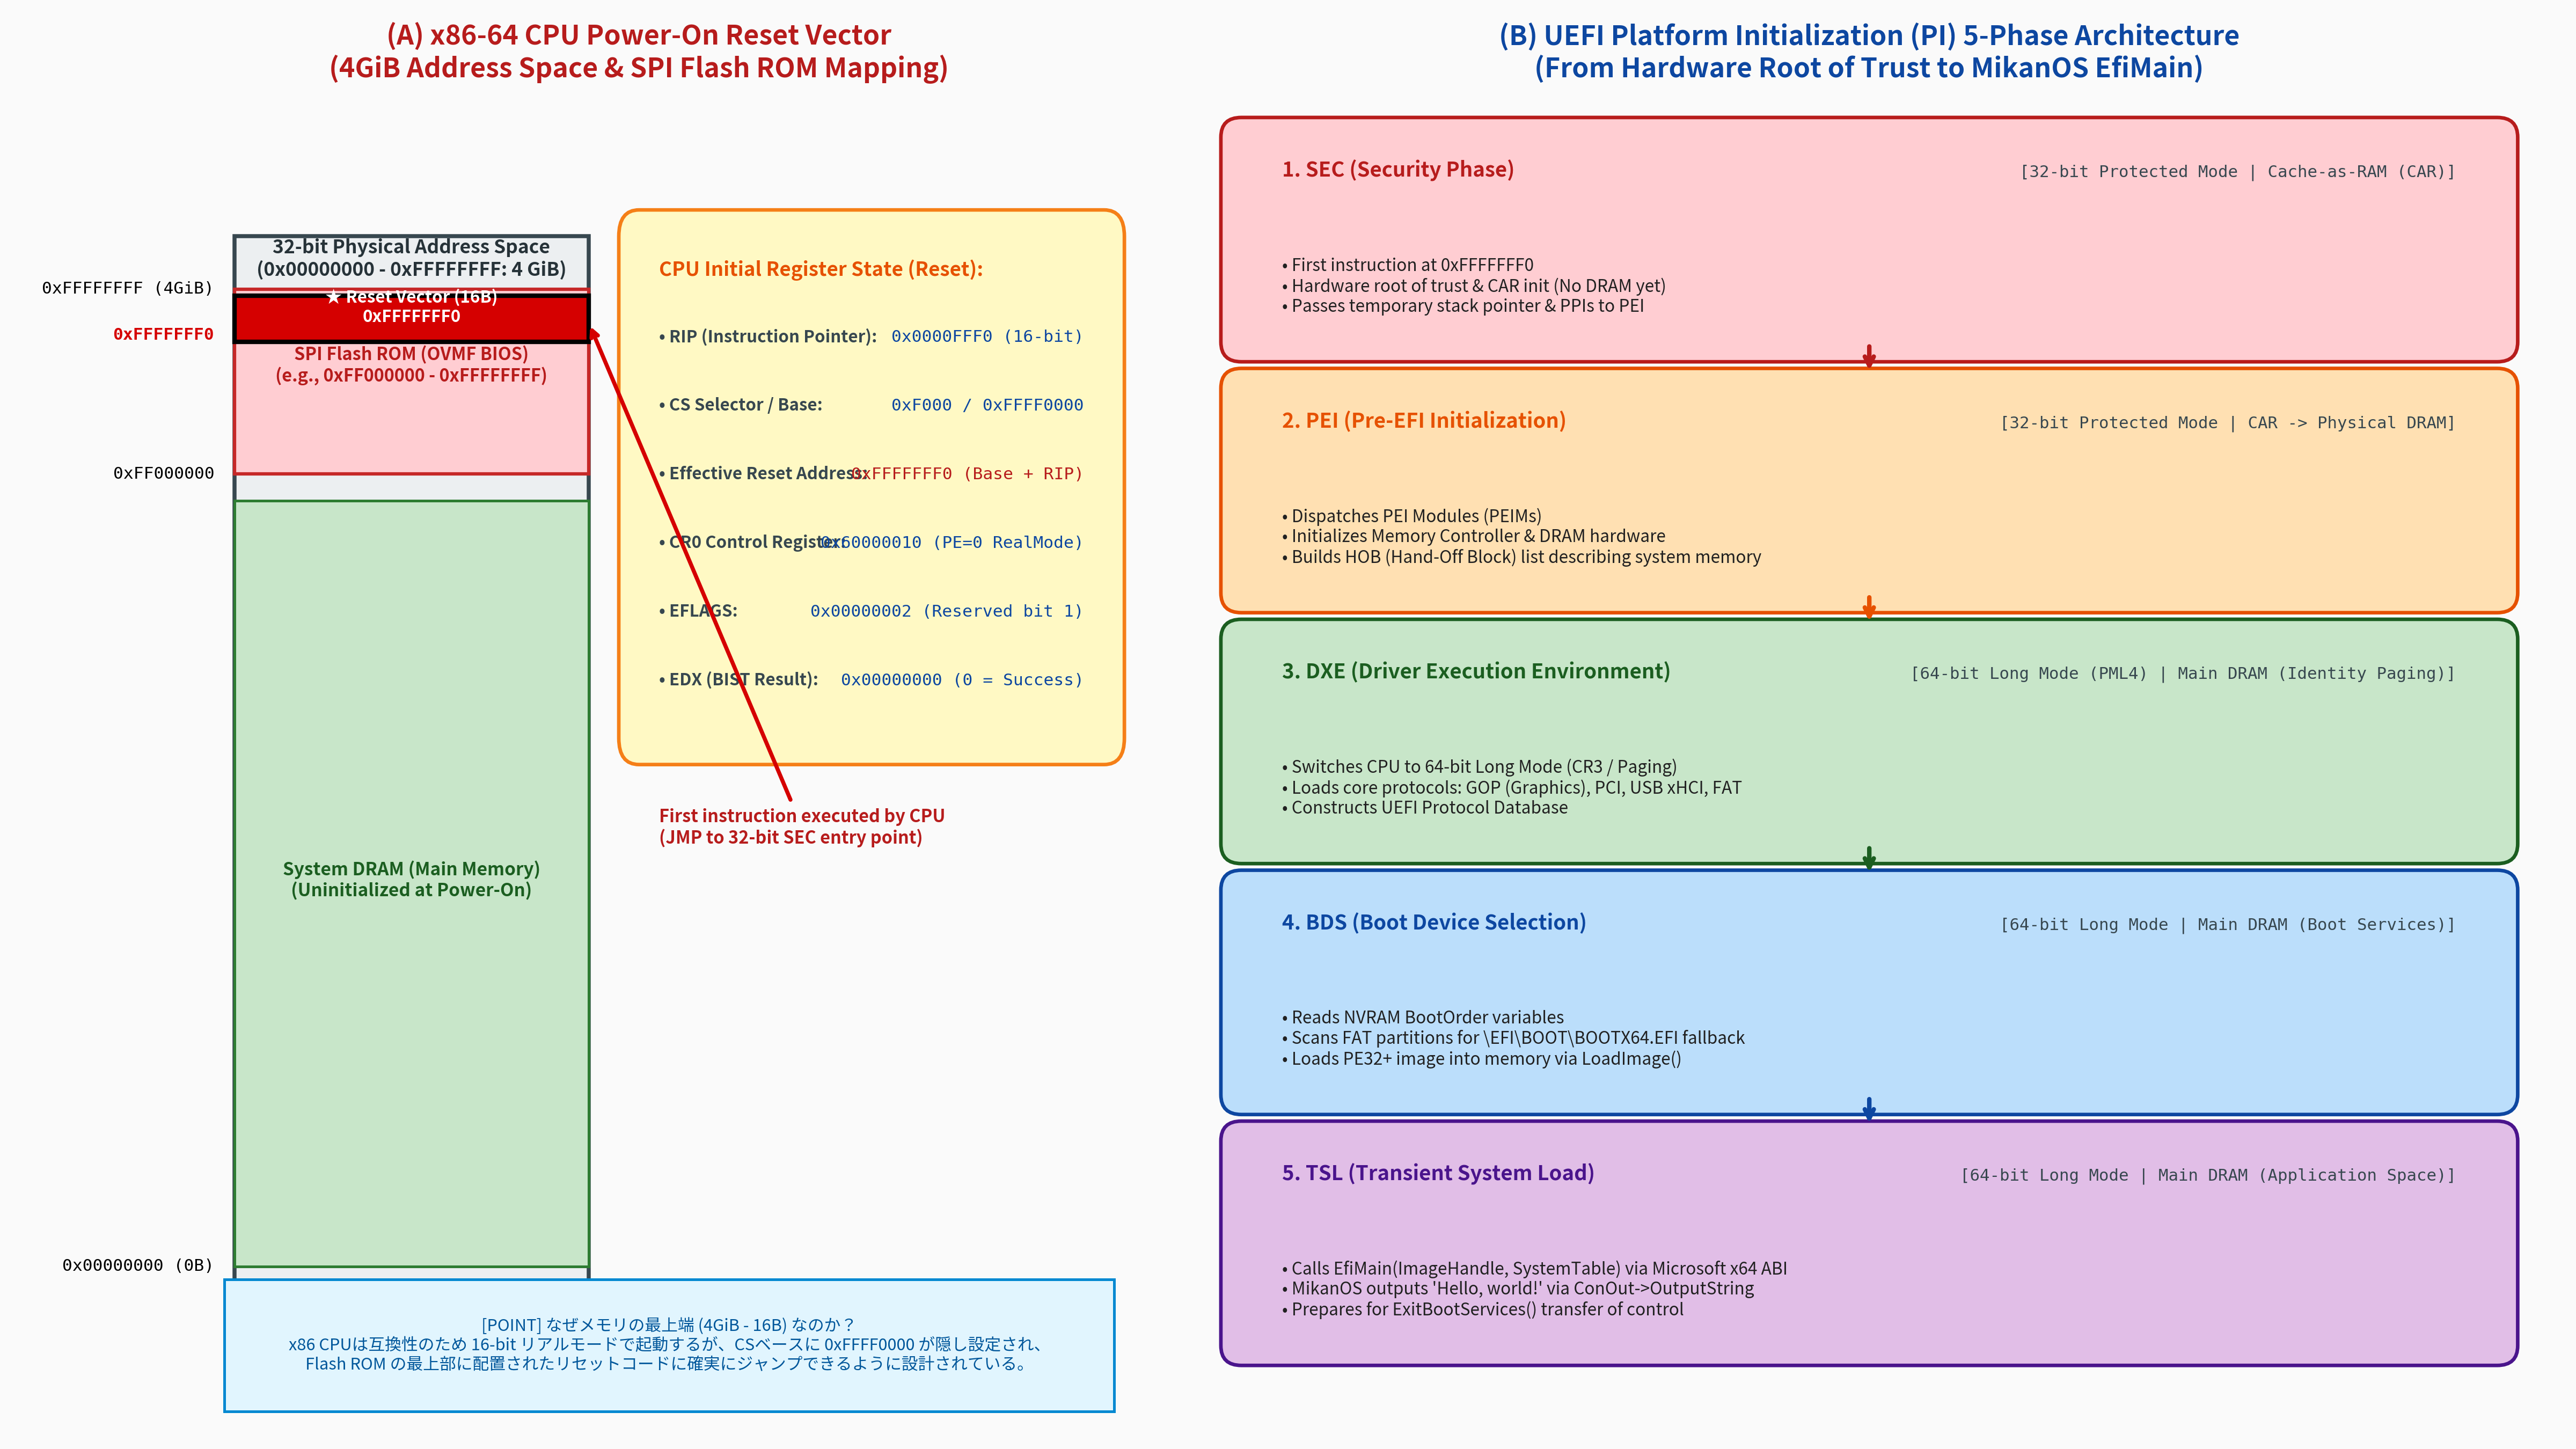

In [3]:
# 高解像度アーキテクチャ図版: CPU リセットベクタと UEFI PI 5大フェーズ
from IPython.display import Image, display
from common import plot_cpu_reset_to_uefi_phases

fig_path = plot_cpu_reset_to_uefi_phases("result/fig1_9_cpu_reset_to_uefi_phases.png")
display(Image(fig_path))


## 3. UEFI ブートマネージャの探索ポリシーと標準パスフォールバック

### なぜ `/EFI/BOOT/BOOTX64.EFI` でなければならないのか？

1.1〜1.4 節において、私たちは USB メモリのルートディレクトリに `EFI` フォルダを作り、その中に `BOOT` フォルダを作り、バイナリを `BOOTX64.EFI` という名前で保存しました。
なぜこの名前でないと動かないのでしょうか？ `MYOS.EFI` や `HELLO.EXE` ではダメだったのでしょうか？

その理由は、**UEFI Specification (Version 2.9+, Section 3.5.1.1 "Removable Media Boot Behavior")** という国際規格の中で、以下のように厳密に定められているからです：

> *"When booting from a removable media device, the file path `\EFI\BOOT\BOOT{machine_type_short_name}.EFI` shall be used. In this case, `machine_type_short_name` reflects the processor architecture."*

### アーキテクチャ別標準フォールバックファイル名一覧

UEFI 仕様書では、CPU のアーキテクチャごとに以下のファイル名が予約されています：

| ターゲットアーキテクチャ | ビット長 | 仕様書予約フォールバックパス | 備考・代表デバイス |
|---|:---:|---|---|
| **x86-64 (AMD64 / Intel 64)** | **64-bit** | **`\EFI\BOOT\BOOTX64.EFI`** | **一般的な PC, 本書 MikanOS の対象** |
| **AArch64 (ARM 64-bit)** | 64-bit | `\EFI\BOOT\BOOTAA64.EFI` | Raspberry Pi 4, Apple Silicon Mac, ARM PC |
| **IA-32 (x86 32-bit)** | 32-bit | `\EFI\BOOT\BOOTIA32.EFI` | 初期の Intel Atom タブレット, 32bit UEFI PC |
| **ARM (Thumb-2 32-bit)** | 32-bit | `\EFI\BOOT\BOOTARM.EFI` | 組込み ARM Cortex-A デバイス |
| **RISC-V 64-bit** | 64-bit | `\EFI\BOOT\BOOTRISCV64.EFI` | 次世代オープン ISA ボード |

もし USB メモリに `\EFI\BOOT\BOOTX64.EFI` と `\EFI\BOOT\BOOTAA64.EFI` の両方を配置しておけば、その USB メモリは **「x86-64 PC に挿せば x86-64 版が、Raspberry Pi に挿せば ARM64 版が全自動でブートするマルチアーキテクチャ対応メディア」** になります。

---

### UEFI BDS ブートターゲット解決の決定木

UEFI のファームウェアは、接続されたストレージを以下の優先順位（決定木）で走査します：

1. **NVRAM `BootOrder` リストの走査**:
   - マザーボードの不揮発性メモリ（NVRAM）に保存されている `Boot0001`, `Boot0002` などのエントリを順番にチェックします。
   - ここには例えば `"PciRoot(0x0)/Pci(0x1F,0x2)/.../File(\EFI\ubuntu\shimx64.efi)"` のような完全なハードウェアパスが記録されています。
2. **リムーバブルメディア（USB / 仮想FAT）のフォールバック探索**:
   - NVRAM に登録された OS が起動できない（または未インストールの新規マシン、あるいはブートメニューで USB を選択した）場合、接続されているリムーバブルストレージの走査を開始します。
   - パーティションテーブル（GPT または MBR）を解析し、ファイルシステムが **FAT (FAT32, FAT16, FAT12)** であるパーティション（ESP: *EFI System Partition*）を探します。
     - ※UEFI 仕様上、NTFS や Linux ext4 などのファイルシステムは標準ファームウェアでは認識されません。
   - FAT パーティションのルートから `EFI` ディレクトリ → `BOOT` ディレクトリへと降り、現在の CPU アーキテクチャに合致する `BOOTX64.EFI` が存在するかを検索します。
   - 発見された場合、直ちにそのバイナリをメモリへロードし、実行を開始します。


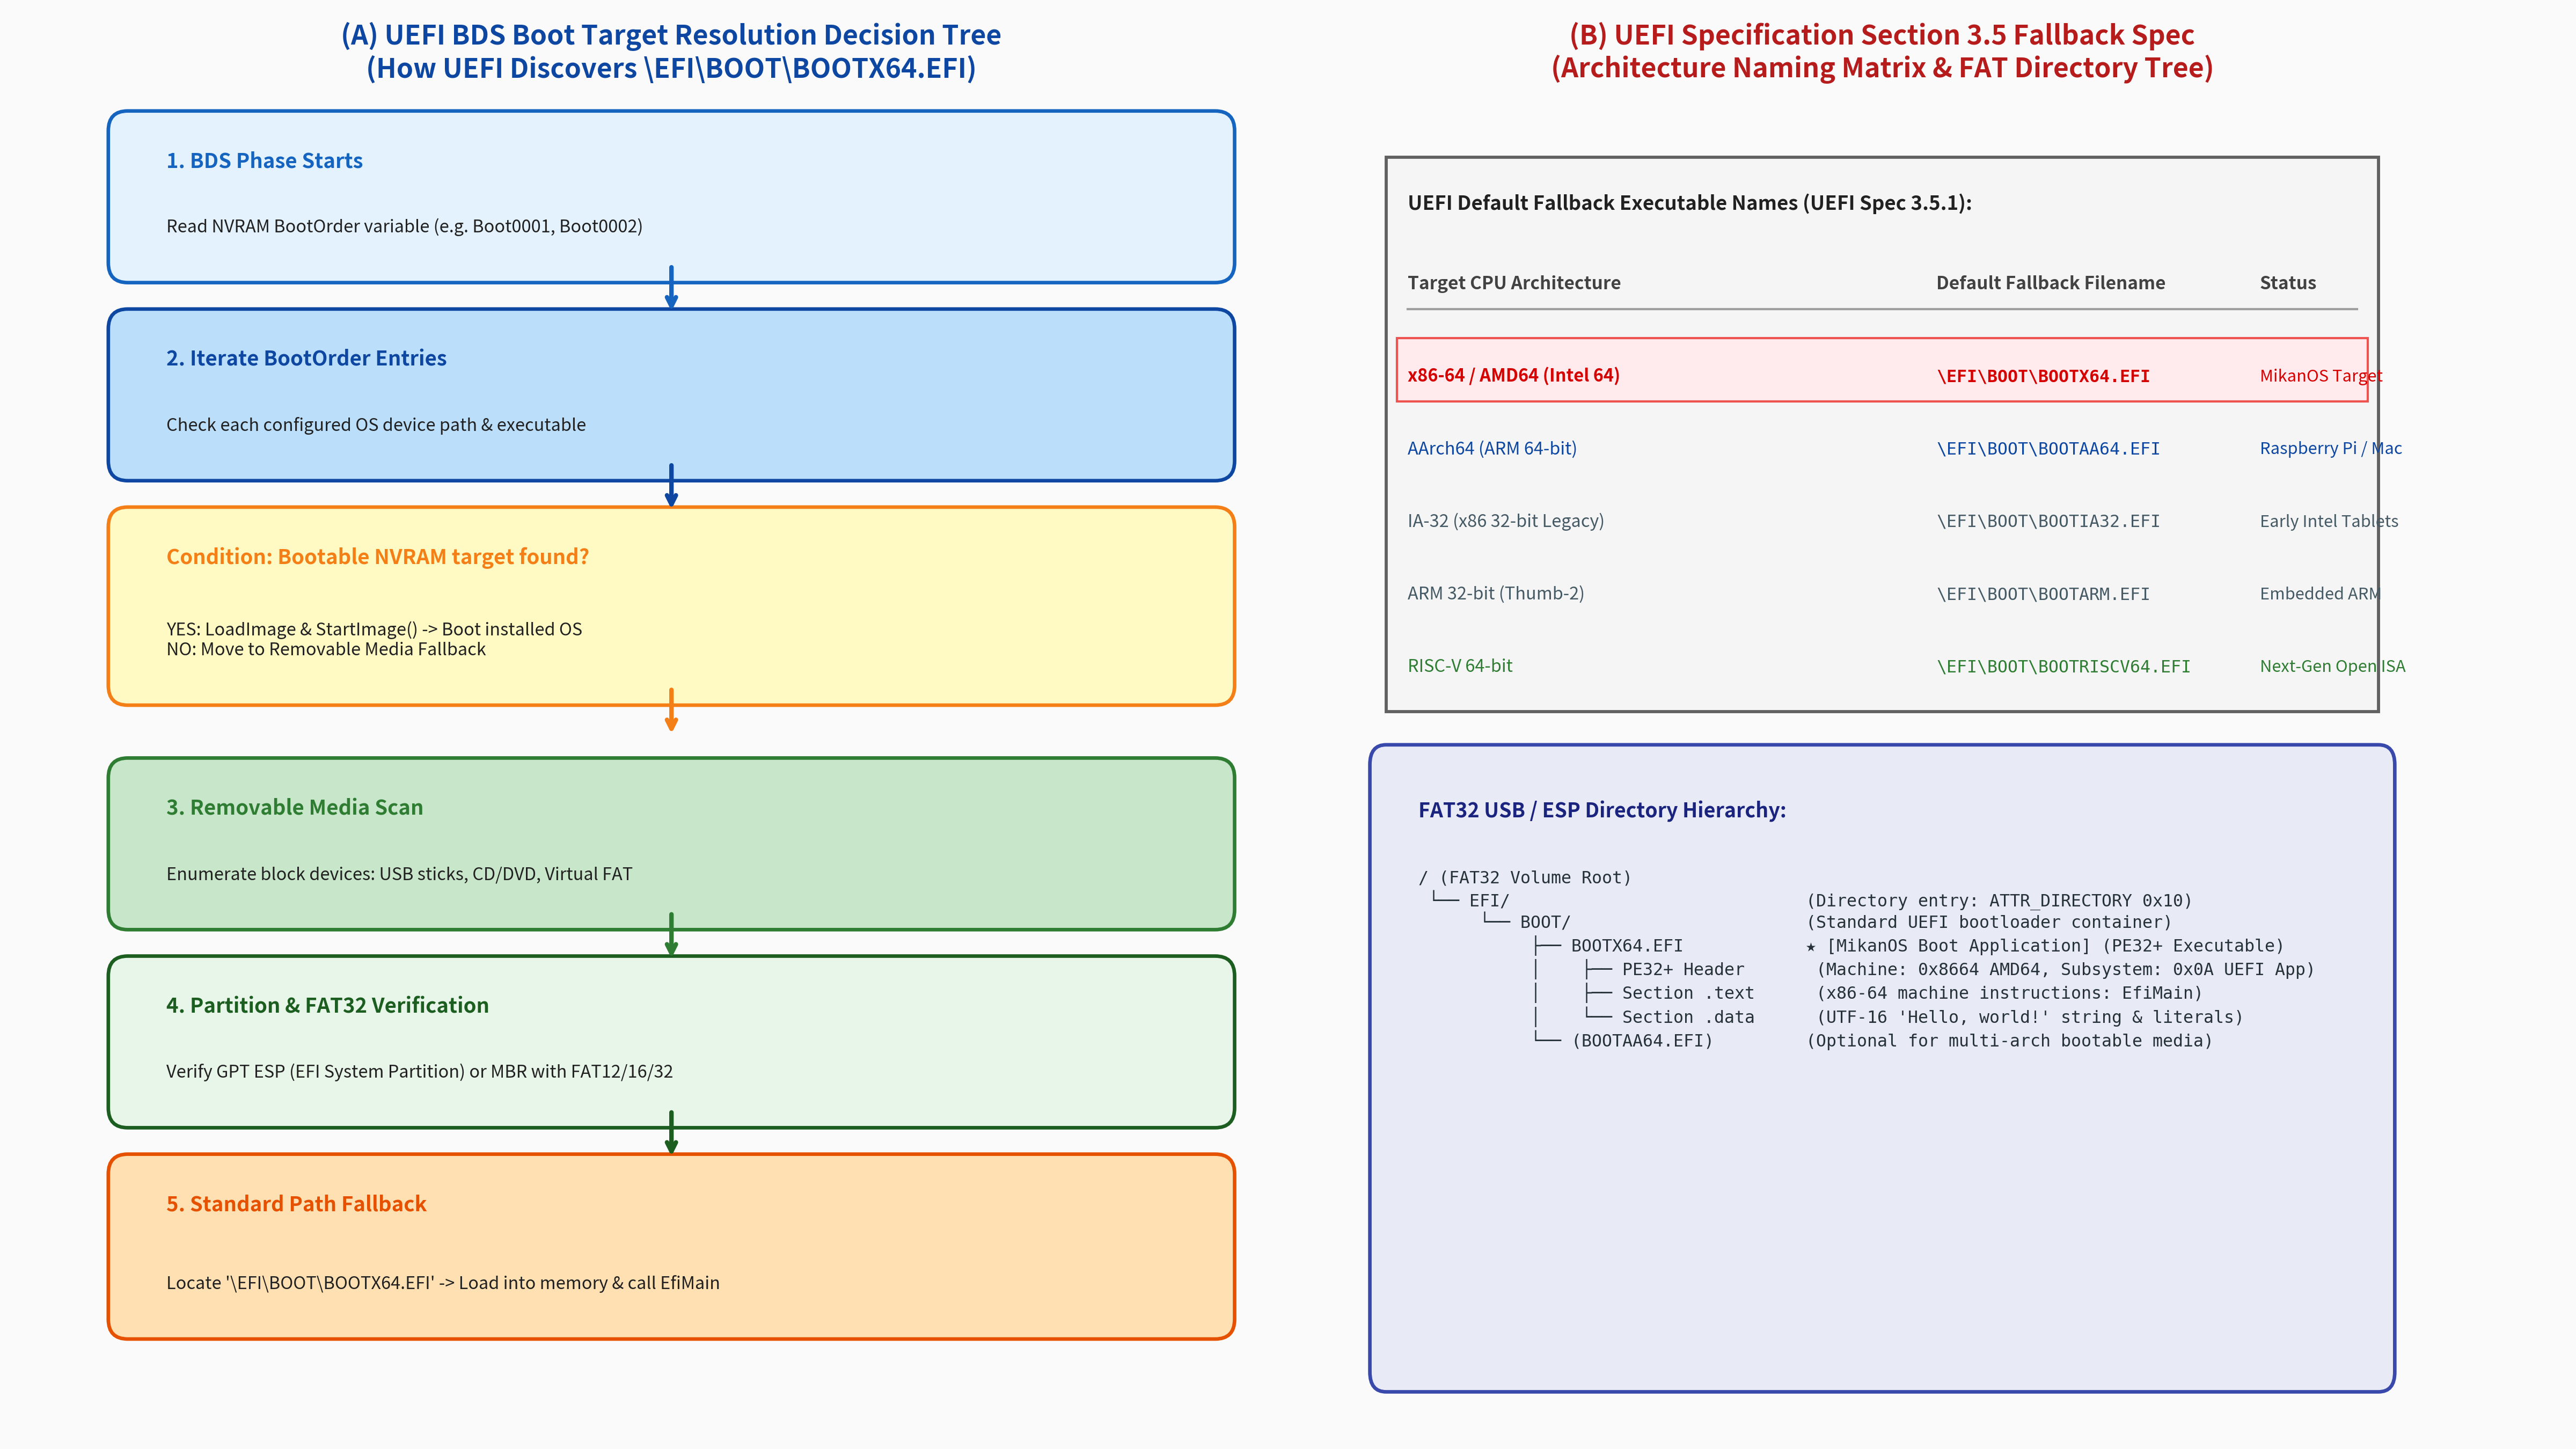

In [4]:
# 高解像度アーキテクチャ図版: UEFI ブートターゲット探索決定木と標準パス仕様
from IPython.display import Image, display
from common import plot_uefi_boot_device_and_file_resolution

fig_path = plot_uefi_boot_device_and_file_resolution("result/fig1_10_uefi_boot_device_and_file_resolution.png")
display(Image(fig_path))


## 4. PE32+ (PE/COFF) 実行可能ファイルのメモリロードと再配置 (*Relocation*)

### なぜ Linux なのに ELF ではなく PE32+ なのか？
通常、Linux 上で C++ プログラムをビルドすると **ELF (*Executable and Linkable Format*)** という形式の実行可能ファイルが生成されます。
しかし、UEFI アプリケーションのバイナリ形式は、Windows の `.exe` や `.dll` で採用されている **PE32+ (PE/COFF: *Portable Executable / Common Object File Format*)** でなければなりません。

これは、UEFI の前身である EFI (*Extensible Firmware Interface*) が 1990年代後半に Intel と Microsoft によって共同開発されたという歴史的経緯によるものです。
そのため、私たちが 1.1 節でバイナリエディタで手打ちしたヘッダも、PE32+ の仕様に厳密に従った構造になっていました。

```text
PE32+ バイナリ構造 (hello.efi)
┌──────────────────────────────────────────────┐ 0x000
│ DOS Header ("MZ", e_lfanew = 0x40)          │
├──────────────────────────────────────────────┤ 0x040
│ PE Signature ("PE\0\0")                     │
├──────────────────────────────────────────────┤ 0x044
│ COFF File Header (Machine = 0x8664 AMD64)    │
├──────────────────────────────────────────────┤ 0x058
│ Optional Header (Subsystem = 0x0A UEFI App) │
│ - AddressOfEntryPoint (RVA = 0x1000)         │
│ - ImageBase (e.g. 0x00000000)                │
├──────────────────────────────────────────────┤ 0x118
│ Section Header: .text (実行コード領域)       │
├──────────────────────────────────────────────┤ 0x140
│ Section Header: .data (文字列・データ領域)   │
└──────────────────────────────────────────────┘
```

---

### UEFI PE ローダのメモリロードと再配置 (Relocation)

UEFI ファームウェアが FAT ファイルシステムから `BOOTX64.EFI` を読み込んだ際、内部では以下の処理が実行されます：

1. **メモリページの確保 (`AllocatePages`)**:
   - PE ヘッダの `SizeOfImage`（バイナリ全体が必要とする仮想メモリサイズ）を読み取ります。
   - `gBS->AllocatePages()` を呼び出し、物理 DRAM の空いている領域（4KiB ページ単位）にメモリを確保します（例: アドレス `0x06000000`）。
2. **セクションの展開**:
   - ファイル内の各セクション（`.text`, `.data` 等）を、ヘッダに指定された RVA (*Relative Virtual Address*) のオフセットに従って確保したメモリへコピーします。
3. **ベース再配置 (Base Relocation)**:
   - コンパイル時に想定されていた `ImageBase` と、実際にファームウェアが割り当てた物理アドレスとの差分（デルタ）を計算し、バイナリ内の絶対メモリアドレス参照を書き換えます。
4. **エントリポイントへのジャンプ (Microsoft x64 ABI)**:
   - ヘッダの `AddressOfEntryPoint` を足したアドレス（`ImageBase + EntryPointRVA`）に制御を移します。

この関数呼び出し時、レジスタは **Microsoft x64 呼び出し規約** に従って以下のように準備されます：
- **`RCX`**: 第1引数 `EFI_HANDLE ImageHandle`（ロードされた自身を示すハンドル）
- **`RDX`**: 第2引数 `EFI_SYSTEM_TABLE* SystemTable`（UEFI 全サービスへのポインタ）
- **`RSP`**: 16バイトアライメント（`RSP % 16 == 0`）＋ 32バイトのシャドウスペース（*Shadow Space*）確保


In [5]:
# Python による UEFI BDS ブートマネージャ探索・決定木のシミュレーション
from common import (
    TargetArchitecture, StorageVolume, NvramBootEntry, UefiBootManagerSimulator
)

bm = UefiBootManagerSimulator(TargetArchitecture.X86_64)

# 状況 1: 内蔵 NVMe ドライブ (OS未インストール / 破損)
nvme_vol = StorageVolume(
    label="NVMe_ESP",
    partition_type="GPT ESP",
    fs_type="FAT32",
    is_removable=False,
    files={}  # 空
)
bm.add_volume(nvme_vol)
bm.add_nvram_entry(NvramBootEntry(
    boot_id=1,
    description="Installed OS (Broken)",
    target_volume_label="NVMe_ESP",
    target_file_path="\\EFI\\ubuntu\\shimx64.efi",
    is_enabled=True
))

# 状況 2: USB メモリ (MikanOS BOOTX64.EFI が配置されている)
usb_vol = StorageVolume(
    label="MIKANOS_BOOT_USB",
    partition_type="MBR FAT",
    fs_type="FAT32",
    is_removable=True,
    files={"EFI/BOOT/BOOTX64.EFI": 1440}
)
bm.add_volume(usb_vol)

# ブート探索の実行
report = bm.resolve()

print("=" * 70)
print("UEFI BDS Boot Target Resolution Simulation Output")
print("=" * 70)
for log in report.log_trace:
    print(log)

print("\n" + "-" * 70)
print(f"結果判定: {'SUCCESS (起動成功)' if report.success else 'FAILED'}")
print(f"解決方法: {report.resolution_method}")
print(f"選択ドライブ: [{report.selected_volume}]")
print(f"ロードファイル: {report.resolved_file_path}")
print("-" * 70)

assert report.success is True
assert report.resolved_file_path == "\\EFI\\BOOT\\BOOTX64.EFI"
print("✅ リムーバブルメディアフォールバックによる BOOTX64.EFI 検出が完璧に実証されました。")


UEFI BDS Boot Target Resolution Simulation Output
[BDS Phase] Initiating boot resolution for architecture: x86-64 (AMD64 / Intel 64)
[BDS Phase] Standard fallback path: \EFI\BOOT\BOOTX64.EFI
Step 1: Inspecting NVRAM BootOrder (1 configured entries)
  Evaluating Boot0001: Installed OS (Broken) -> [NVMe_ESP] \EFI\ubuntu\shimx64.efi
  Target file not found or incompatible FS on [NVMe_ESP]
Step 2: No bootable NVRAM target succeeded. Initiating Removable Media Fallback...
  Probing volume [NVMe_ESP] (Type: GPT ESP, FS: FAT32, Removable: False)
    Fallback binary '\EFI\BOOT\BOOTX64.EFI' not present on [NVMe_ESP]
  Probing volume [MIKANOS_BOOT_USB] (Type: MBR FAT, FS: FAT32, Removable: True)
    --> SUCCESS: Located canonical fallback binary '\EFI\BOOT\BOOTX64.EFI' on [MIKANOS_BOOT_USB]

----------------------------------------------------------------------
結果判定: SUCCESS (起動成功)
解決方法: Removable Media Fallback (\EFI\BOOT\BOOTX64.EFI)
選択ドライブ: [MIKANOS_BOOT_USB]
ロードファイル: \EFI\BOOT\BOOTX64.EFI
--

## 5. `EFI_SYSTEM_TABLE` と `ConOut->OutputString` — 画面出力の舞台裏

### システムテーブルの正体
`EfiMain` 関数に渡された第2引数 `EFI_SYSTEM_TABLE` は、OS 自作者が UEFI のすべての機能にアクセスするための**「唯一にして最強の万能テーブル」**です。

```c
typedef struct {
    EFI_TABLE_HEADER                Hdr;
    CHAR16                          *FirmwareVendor;
    UINT32                          FirmwareRevision;
    EFI_HANDLE                      ConsoleInHandle;
    EFI_SIMPLE_TEXT_INPUT_PROTOCOL  *ConIn;
    EFI_HANDLE                      ConsoleOutHandle;
    EFI_SIMPLE_TEXT_OUTPUT_PROTOCOL *ConOut;   // ★ 画面出力プロトコル
    EFI_HANDLE                      StandardErrorHandle;
    EFI_SIMPLE_TEXT_OUTPUT_PROTOCOL *StdErr;
    EFI_RUNTIME_SERVICES            *RuntimeServices;
    EFI_BOOT_SERVICES               *BootServices;
} EFI_SYSTEM_TABLE;
```

私たちが 1.1 節で機械語として実行したのは、実質的に以下の C 言語コードでした：

```c
SystemTable->ConOut->OutputString(SystemTable->ConOut, u"Hello, world\r\n");
```

---

### なぜ `printf` ではなくポインタのポインタ呼び出しなのか？
私たちが普段 C 言語で書く `printf("Hello, world\n")` は、OS（Linux や Windows）が提供する C 標準ライブラリ（glibc や MSVCRT）が裏でシステムコール（`write` など）を発行することで実現しています。
しかし、電源が入った直後の PC には標準 C ライブラリも OS も存在しません（**フリースタンディング環境**）。

そのため、ハードウェアの画面を制御できる唯一の存在である **UEFI ファームウェアが提供する関数ポインタ（`OutputString`）** を、構造体ポインタを手繰り寄せて呼び出す必要があったのです。

### なぜ文字列が UTF-16 なのか？
UEFI の仕様では、画面出力やファイル名などの文字列はすべて **16ビット Unicode (UCS-2 / UTF-16)** で扱うことが定められています。
そのため、`'H'` という1文字は `0x48`（1バイト）ではなく、`0x0048`（2バイト：リトルエンディアンで `48 00`）としてメモリに配置しなければならなかったのです。

### 文字列が画面に届くまでの物理的経路
`OutputString` が呼び出されたとき、UEFI ファームウェアの内部ドライバは以下の処理を行っています：
1. 文字コード（UTF-16）に対応するビットマップフォントデータを ROM 内から探索。
2. **GOP (*Graphics Output Protocol*)** が管理するグラフィックスカードの **フレームバッファ（VRAM: *Video RAM*）** の指定ピクセル座標に、フォントのピクセルを描画。
3. 同時に、デバッグ用にシリアルポート（COM1 / I/O ポート `0x3F8`）が接続されていれば、そこへ同じ文字列を送信。

こうして、私たちが打ち込んだ機械語によって、ディスプレイに `"Hello, world"` という白い文字が灯ったのです！


## 6. C++20 スタンドアロン検証ツールによるブートシーケンス完全追跡

リポジトリ内の `src/ch01/boot_sequence_tracer.cpp` には、本節で解説した CPU リセットベクタ、UEFI PI 5大フェーズ、BDS 決定木、Microsoft x64 ABI レジスタ状態、および ConOut UTF-16 文字列デコーダを網羅した C++20 ホスト側検証ツールが実装されています。

以下のセルを実行して CMake でビルド・実行し、仕様の整合性を検証してみましょう。


In [6]:
# C++20 スタンドアロン検証ツールのビルド & 実行
import subprocess
from pathlib import Path

repo_root = Path.cwd().parent if Path.cwd().name == '1' else Path.cwd()
build_dir = repo_root / "build"
binary = build_dir / "bin" / "ch01_boot_sequence_tracer"

# CMake ビルドの実行
subprocess.run(["cmake", "--build", str(build_dir), "--target", "ch01_boot_sequence_tracer"], check=True)

# セルフテストの実行
res_test = subprocess.run([str(binary), "--test"], capture_output=True, text=True, check=True)
print(res_test.stdout.strip())

# トレース実行
res_run = subprocess.run([str(binary)], capture_output=True, text=True, check=True)
print(res_run.stdout)


[100%] Built target ch01_boot_sequence_tracer
All C++20 Boot Sequence Tracer Self-Tests Passed Successfully!
🍊 MikanOS Chapter 1.5: Behind the Scenes Boot Sequence Tracer

>>> 1. Hardware Reset State <<<
=== x86-64 CPU Power-On Reset State (Intel SDM Vol 3A 9.1) ===
  Initial Physical Address (Reset Vector): 0xFFFFFFF0 (4GiB - 16 bytes)
  CS:IP Selector / Offset: 0xF000:0xFFF0
  CS Hidden Base Address:  0xFFFF0000
  CR0 Register:            0x60000010 (PE=0 RealMode, CD=1 CacheDisable)
  EFLAGS Register:         0x2
  EDX BIST Result:         0x0 (BIST PASSED)

>>> 2. UEFI Platform Initialization (PI) 5-Phase Architecture <<<
-----------------------------------------------------------------
Phase: SEC (Security Phase)
  CPU Mode: 32-bit Protected Mode (Flat)
  Memory:   Cache-as-RAM (CAR / Temporary RAM in L1/L2 Cache)
  Role:     Hardware root of trust, CAR init, transition out of 16-bit Reset Vector
  Key Events:
    * CPU executes at Reset Vector 0xFFFFFFF0
    * Switches to 32-bit 

## 7. 理解度セルフチェック演習（即時自己採点）

本節で学んだ低レイヤ・ブートシーケンスの核心について、以下の4つの設問に答えて理解度を確認してください。
下の Python セル内の解答変数を書き換えて実行することで、即座に自己採点が行われます。

---

### 設問一覧

#### 【問1】CPU リセットベクタ
x86-64 CPU がハードウェアリセット直後に最初に命令をフェッチする物理アドレスとして正しいものはどれですか？
- A) `0x00000000` (メインメモリの先頭)
- B) `0x00007C00` (レガシー BIOS MBR ロードアドレス)
- C) `0xFFFFFFF0` (32ビットアドレス空間最上部 4GiB の 16バイト手前)
- D) `0x7C000000` (UEFI ファームウェアのエントリポイント)

#### 【問2】UEFI 5大フェーズとメモリ
UEFI PI 仕様において、マザーボード上の物理 DRAM（メインメモリ）コントローラが初期化され、DRAM が利用可能になるフェーズはどれですか？
- A) SEC (Security Phase)
- B) PEI (Pre-EFI Initialization Phase)
- C) DXE (Driver Execution Environment Phase)
- D) BDS (Boot Device Selection Phase)

#### 【問3】標準ブートフォールバックパス
UEFI 仕様書 Section 3.5 に基づき、x86-64 (AMD64) アーキテクチャのリムーバブルメディア（USBメモリ等）で探索される標準ブートローダファイル名はどれですか？
- A) `\EFI\BOOT\BOOTX64.EFI`
- B) `\EFI\BOOT\BOOTAA64.EFI`
- C) `\BOOT\KERNEL.BIN`
- D) `\EFI\SYSTEM\START.EXE`

#### 【問4】EfiMain 呼び出し規約
UEFI アプリケーションのエントリポイント `EfiMain` がファームウェアから呼び出される際、第2引数である `EFI_SYSTEM_TABLE* SystemTable` が格納されているレジスタはどれですか？ (Microsoft x64 ABI)
- A) `RAX`
- B) `RDI`
- C) `RCX`
- D) `RDX`


In [7]:
# === 理解度セルフチェック演習（解答入力セル） ===
# [設問への回答を A / B / C / D で指定してください]

ans_q1 = "C"  # 問1: CPU リセットベクタの物理アドレス
ans_q2 = "B"  # 問2: DRAM コントローラが初期化されるフェーズ
ans_q3 = "A"  # 問3: x86-64 標準ブートフォールバックファイル名
ans_q4 = "D"  # 問4: SystemTable が渡されるレジスタ (Microsoft x64 ABI)

# 採点スクリプト
correct_answers = {
    "問1 (リセットベクタ)": ("C", "0xFFFFFFF0 (4GiB - 16バイト) です。Flash ROM最上端から実行を開始します。"),
    "問2 (DRAM初期化)": ("B", "PEI フェーズです。SECではCache-as-RAMを使い、PEIでDRAMを初期化してHOBを作成します。"),
    "問3 (標準ファイル名)": ("A", "\\EFI\\BOOT\\BOOTX64.EFI です。ARM64なら BOOTAA64.EFI となります。"),
    "問4 (SystemTable引数)": ("D", "RDX レジスタです。Microsoft x64 ABI では第1引数RCX (ImageHandle)、第2引数RDX (SystemTable) です。"),
}

user_answers = [ans_q1, ans_q2, ans_q3, ans_q4]
score = 0

print("=" * 65)
print("🎯 第1章 1.5節 理解度セルフチェック 採点結果")
print("=" * 65)

for idx, (title, (correct, exp)) in enumerate(correct_answers.items()):
    user = user_answers[idx].strip().upper()
    is_correct = (user == correct)
    if is_correct:
        score += 25
        print(f"✅ {title}: 正解 ({user})")
    else:
        print(f"❌ {title}: 不正解 (あなたの回答: {user} / 正解: {correct})")
    print(f"   解説: {exp}\n")

print("-" * 65)
print(f"総合得点: {score} / 100 点")
if score == 100:
    print("🏆 完璧です！CPUリセットからUEFIアプリケーション起動までの全シーケンスを完全マスターしました！")
else:
    print("💡 間違えた問題の解説とノートブック本文を再確認してみましょう。")
print("-" * 65)

assert score == 100, f"Score must be 100/100, but got {score}"


🎯 第1章 1.5節 理解度セルフチェック 採点結果
✅ 問1 (リセットベクタ): 正解 (C)
   解説: 0xFFFFFFF0 (4GiB - 16バイト) です。Flash ROM最上端から実行を開始します。

✅ 問2 (DRAM初期化): 正解 (B)
   解説: PEI フェーズです。SECではCache-as-RAMを使い、PEIでDRAMを初期化してHOBを作成します。

✅ 問3 (標準ファイル名): 正解 (A)
   解説: \EFI\BOOT\BOOTX64.EFI です。ARM64なら BOOTAA64.EFI となります。

✅ 問4 (SystemTable引数): 正解 (D)
   解説: RDX レジスタです。Microsoft x64 ABI では第1引数RCX (ImageHandle)、第2引数RDX (SystemTable) です。

-----------------------------------------------------------------
総合得点: 100 / 100 点
🏆 完璧です！CPUリセットからUEFIアプリケーション起動までの全シーケンスを完全マスターしました！
-----------------------------------------------------------------


## 8. 本節のまとめと次節（1.6 節「とにかく手を動かそう」＆ 1.7 節「UEFI BIOSによる起動」）への展望

### 本節で学んだ重要概念 (Key Takeaways)
1. **リセットベクタ `0xFFFFFFF0` の必然性**:
   - x86-64 CPU は 16ビットリアルモード相当で立ち上がるが、`CS` ベースアドレスに `0xFFFF0000` がセットされており、物理メモリ最上端（4GiB - 16B）の SPI Flash ROM 直結アドレスから即座にジャンプ命令を実行する。
2. **UEFI PI 5大フェーズの段階的ハードウェア立ち上げ**:
   - メモリがない初期状態の **SEC**（Cache-as-RAM）から、DRAM を初期化する **PEI**、64ビット Long Mode とページングを有効化してドライバを展開する **DXE**、ブートターゲットを解決する **BDS**、そしてアプリを実行する **TSL** へと、ハードウェア資源をスモールステップで獲得していく。
3. **UEFI 標準フォールバック探索（Section 3.5）**:
   - リムーバブルメディア（USBメモリや仮想FAT）では、規格で定められた `\EFI\BOOT\BOOTX64.EFI` という階層構造と命名規則に従うことで、NVRAM 設定なしでも自動検出・自動起動される。
4. **PE32+ 形式と Microsoft x64 呼び出し規約**:
   - UEFI は OS より前に動くため、静的リンクされた C ランタイムではなく `EFI_SYSTEM_TABLE` へのポインタを `RDX`（第2引数）で受け取り、その中の `ConOut->OutputString` 関数ポインタ経由で UTF-16 文字列を画面フレームバッファへ描画する。

---

### 次節への展望 (Next Steps)
- **1.6 とにかく手を動かそう (`1/1.6_Hands_On_Mindset.ipynb`)**:
  - 低レイヤ・OS 自作における「実験と観察のサイクル」と、バイナリ改造による動作変化の観察思考法を確立します。
- **1.7 UEFI BIOSによる起動 (`1/1.7_Booting_with_UEFI_BIOS.ipynb`)**:
  - かつての「レガシー BIOS（16ビット・MBR 512バイト制限・リアルモード）」と現代の「UEFI（64ビット・GPT・FATファイルシステム）」の決定的な技術的断絶と進化の歴史を深掘りします。
- **1.8〜1.9 C言語でハローワールド**:
  - バイナリエディタによる機械語手打ちを卒業し、C 言語（Clang/LLVM）による本物の UEFI アプリケーション開発へとステップアップします！
